In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, f1_score,
                             precision_score, recall_score, roc_auc_score)

sys.path.insert(0, str(Path("..").resolve() / "src"))
from model_prep import FEATURES, NUMERIC, build_preprocessor, get_splits

X_train, y_train, X_val, y_val, X_test, y_test = get_splits()

print("equity_ratio still in features:", "equity_ratio" in FEATURES)
for name, y in [("train 2015-2019", y_train), ("val 2020", y_val), ("test 2021", y_test)]:
    print(f"{name:16s} {len(y):>6,} rows   {y.mean():.3f} distressed")

equity_ratio still in features: False
train 2015-2019  22,897 rows   0.313 distressed
val 2020          4,531 rows   0.266 distressed
test 2021         4,505 rows   0.423 distressed


In [3]:
results = []

def evaluate(name, y_true, scores, threshold=0.5, split="val"):
    """Score one model and add a row to the results table."""
    scores = np.asarray(scores)
    pred = (scores >= threshold).astype(int)
    row = {
        "model": name, "split": split, "threshold": threshold,
        "pr_auc": average_precision_score(y_true, scores),
        "roc_auc": roc_auc_score(y_true, scores),
        "recall": recall_score(y_true, pred, zero_division=0),
        "precision": precision_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "flagged_pct": pred.mean(),
    }
    results.append(row)
    return row

def show_results():
    return pd.DataFrame(results).round(3)

In [4]:
# Floor: a random model's PR-AUC equals the share of distressed hospitals
print(f"Random-guess PR-AUC floor (val): {y_val.mean():.3f}")

# Persistence rule from the paper: distressed next year if total margin < 0 now
margin = X_val["total_margin"].fillna(X_train["total_margin"].median())
evaluate("Rule: margin < 0 now", y_val, (margin < 0).astype(int), threshold=1)

# Same idea as a ranking: lower margin = higher risk
evaluate("Ranking: -total margin", y_val, -margin, threshold=0)

show_results()

Random-guess PR-AUC floor (val): 0.266


,model,split,threshold,pr_auc,roc_auc,recall,precision,f1,flagged_pct
0,Rule: margin < 0 now,val,1,0.379,0.644,0.423,0.533,0.472,0.211
1,Ranking: -total margin,val,0,0.501,0.684,0.423,0.533,0.472,0.211


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

def make_logit(C=1.0, class_weight="balanced"):
    return Pipeline([
        ("prep", build_preprocessor()),
        ("clf", LogisticRegression(C=C, class_weight=class_weight, max_iter=5000)),
    ])

logit_plain = make_logit(class_weight=None).fit(X_train, y_train)
evaluate("Logit (no weights)", y_val, logit_plain.predict_proba(X_val)[:, 1])

logit = make_logit().fit(X_train, y_train)
p_logit = logit.predict_proba(X_val)[:, 1]
evaluate("Logit (balanced)", y_val, p_logit)

show_results()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,model,split,threshold,pr_auc,roc_auc,recall,precision,f1,flagged_pct
0,Rule: margin < 0 now,val,1.0,0.379,0.644,0.423,0.533,0.472,0.211
1,Ranking: -total margin,val,0.0,0.501,0.684,0.423,0.533,0.472,0.211
2,Logit (no weights),val,0.5,0.538,0.731,0.320,0.620,0.422,0.137
3,Logit (balanced),val,0.5,0.537,0.732,0.518,0.513,0.515,0.269


In [6]:
# Smaller C = stronger L2 penalty. Just a quick look; not added to the results table.
for C in [0.01, 0.1, 1, 10]:
    p = make_logit(C=C).fit(X_train, y_train).predict_proba(X_val)[:, 1]
    print(f"C={C:<5}  PR-AUC {average_precision_score(y_val, p):.3f}   "
          f"ROC-AUC {roc_auc_score(y_val, p):.3f}")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


C=0.01   PR-AUC 0.538   ROC-AUC 0.732


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


C=0.1    PR-AUC 0.538   ROC-AUC 0.732


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


C=1      PR-AUC 0.537   ROC-AUC 0.732
C=10     PR-AUC 0.537   ROC-AUC 0.732


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


In [7]:
names = logit.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logit.named_steps["clf"].coef_[0], index=names)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15).round(3)

num__total_margin                              -1.157
num__log_revenue                               -0.448
flag__neg_margin_last_year                      0.406
num__missingindicator_days_cash_on_hand_chg     0.395
flag__negative_liabilities                     -0.381
num__missingindicator_days_cash_on_hand_lag1   -0.335
num__debt_ratio                                 0.329
cat__ccn_facility_type_CAH                     -0.321
num__operating_margin                          -0.292
num__total_margin_lag1                         -0.233
num__operating_margin_lag1                      0.230
num__days_cash_on_hand                         -0.218
num__missingindicator_total_margin_lag1         0.215
num__missingindicator_debt_ratio_chg           -0.206
num__missingindicator_operating_margin_lag1     0.165
dtype: float64

In [8]:
import sqlite3
from model_prep import DB_PATH

with sqlite3.connect(DB_PATH) as conn:
    f = pd.read_sql("""
        SELECT file_year, partial_year, period_days, exited_next, distress_next
        FROM features WHERE distress_next IS NOT NULL
    """, conn)
f["partial_year"] = f["partial_year"].astype(int)

print(f.groupby("partial_year").agg(
    rows=("distress_next", "size"),
    distress_rate=("distress_next", "mean"),
    exit_rate=("exited_next", "mean"),
).round(3))

short = f[f["partial_year"] == 1]
print("\nPartial-year reports by length and exit:")
print(pd.crosstab(pd.cut(short["period_days"], [0, 180, 359, 370, 10_000],
                         labels=["<=6 months", "6-12 months", "~1 year", ">1 year"]),
                  short["exited_next"], margins=True))

               rows  distress_rate  exit_rate
partial_year                                 
0             31002          0.311      0.002
1               931          0.689      0.319

Partial-year reports by length and exit:
exited_next    0    1  All
period_days               
<=6 months    85   99  184
6-12 months  474  169  643
>1 year       75   29  104
All          634  297  931


In [9]:
# How much of the score comes from terminating reports (partial year + exit)?
with sqlite3.connect(DB_PATH) as conn:
    v = pd.read_sql("""
        SELECT partial_year, exited_next FROM features
        WHERE distress_next IS NOT NULL AND file_year = 2020
    """, conn)
assert len(v) == len(y_val), "row order mismatch, tell Claude"

terminating = ((v["partial_year"].astype(int) == 1) & (v["exited_next"] == 1)).to_numpy()
print("Terminating reports in validation:", terminating.sum())

keep = ~terminating
evaluate("Logit (balanced), excl. terminating", y_val[keep], p_logit[keep],
         split="val excl. term.")
show_results()

Terminating reports in validation: 31


,model,split,threshold,pr_auc,roc_auc,recall,precision,f1,flagged_pct
0,Rule: margin < 0 now,val,1.0,0.379,0.644,0.423,0.533,0.472,0.211
1,Ranking: -total margin,val,0.0,0.501,0.684,0.423,0.533,0.472,0.211
2,Logit (no weights),val,0.5,0.538,0.731,0.320,0.620,0.422,0.137
3,Logit (balanced),val,0.5,0.537,0.732,0.518,0.513,0.515,0.269
4,"Logit (balanced), excl. terminating",val excl. term.,0.5,0.520,0.727,0.508,0.501,0.504,0.264


In [10]:
loc = panel_check = None  # placeholder so the cell is self-contained
with sqlite3.connect(DB_PATH) as conn:
    loc = pd.read_sql("""
        SELECT rural_urban, partial_year, exited_next, distress_next
        FROM features WHERE distress_next IS NOT NULL
    """, conn)
loc["rural_urban"] = loc["rural_urban"].fillna("Missing")
print(loc.groupby("rural_urban").agg(
    rows=("distress_next", "size"),
    distress_rate=("distress_next", "mean"),
    exit_rate=("exited_next", "mean"),
    partial_year_rate=("partial_year", "mean"),
).round(3))

              rows  distress_rate  exit_rate  partial_year_rate
rural_urban                                                    
Missing         23          0.826      0.696              0.696
R            15636          0.342      0.010              0.027
U            16274          0.301      0.012              0.030


In [11]:
from model_prep import FLAGS, TARGET

with sqlite3.connect(DB_PATH) as conn:
    panel = pd.read_sql("SELECT * FROM features", conn)
panel = panel[panel[TARGET].notna()].copy()
panel[TARGET] = panel[TARGET].astype(int)
panel[FLAGS] = panel[FLAGS].astype(float)
dev = panel[panel["file_year"] <= 2020]          # test year 2021 stays out

def rolling_folds(first_val=2017, last_val=2020):
    """Train on all years before the validation year, validate on that year."""
    for yr in range(first_val, last_val + 1):
        tr = dev[dev["file_year"] < yr]
        va = dev[dev["file_year"] == yr]
        yield yr, tr[FEATURES], tr[TARGET], va[FEATURES], va[TARGET]

cv_rows = []

def cv_score(name, make_model):
    """make_model(y_train) returns an unfitted model, so class weights can use each fold's labels."""
    scores = {}
    for yr, Xtr, ytr, Xva, yva in rolling_folds():
        p = make_model(ytr).fit(Xtr, ytr).predict_proba(Xva)[:, 1]
        scores[yr] = average_precision_score(yva, p)
    row = {"model": name, **{f"pr_auc_{y}": s for y, s in scores.items()},
           "mean": np.mean(list(scores.values())), "std": np.std(list(scores.values()))}
    cv_rows.append(row)
    return row

cv_score("Logit (balanced)", lambda y: make_logit())
pd.DataFrame(cv_rows).round(3)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,model,pr_auc_2017,pr_auc_2018,pr_auc_2019,pr_auc_2020,mean,std
0,Logit (balanced),0.727,0.69,0.57,0.537,0.631,0.079


In [12]:
from sklearn.ensemble import RandomForestClassifier

def make_rf(min_samples_leaf=20, max_features="sqrt"):
    return Pipeline([
        ("prep", build_preprocessor()),
        ("clf", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=min_samples_leaf,   # bigger = smoother trees, less overfitting
            max_features=max_features,           # share of features tried at each split
            class_weight="balanced_subsample",
            n_jobs=-1, random_state=42,
        )),
    ])

for leaf in [5, 20, 50]:
    for mf in ["sqrt", 0.3]:
        cv_score(f"RF leaf={leaf} max_features={mf}",
                 lambda y, leaf=leaf, mf=mf: make_rf(leaf, mf))

pd.DataFrame(cv_rows).round(3).sort_values("mean", ascending=False)

,model,pr_auc_2017,pr_auc_2018,pr_auc_2019,pr_auc_2020,mean,std
4,RF leaf=20 max_features=0.3,0.753,0.714,0.567,0.579,0.653,0.081
6,RF leaf=50 max_features=0.3,0.750,0.712,0.571,0.573,0.651,0.080
2,RF leaf=5 max_features=0.3,0.747,0.711,0.564,0.583,0.651,0.079
3,RF leaf=20 max_features=sqrt,0.747,0.710,0.564,0.578,0.650,0.080
1,RF leaf=5 max_features=sqrt,0.746,0.711,0.560,0.584,0.650,0.080
5,RF leaf=50 max_features=sqrt,0.743,0.708,0.563,0.572,0.646,0.080
0,Logit (balanced),0.727,0.690,0.570,0.537,0.631,0.079


In [13]:
from xgboost import XGBClassifier

def make_xgb(y, max_depth=4, min_child_weight=1):
    pos_weight = (y == 0).sum() / (y == 1).sum()   # same idea as class_weight="balanced"
    return Pipeline([
        ("prep", build_preprocessor()),
        ("clf", XGBClassifier(
            n_estimators=400,
            learning_rate=0.05,
            max_depth=max_depth,                 # how deep each tree can go
            min_child_weight=min_child_weight,   # bigger = more conservative splits
            subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=pos_weight,
            eval_metric="aucpr",
            n_jobs=-1, random_state=42,
        )),
    ])

for depth in [3, 4, 6]:
    for mcw in [1, 10]:
        cv_score(f"XGB depth={depth} min_child_weight={mcw}",
                 lambda y, d=depth, m=mcw: make_xgb(y, d, m))

pd.DataFrame(cv_rows).round(3).sort_values("mean", ascending=False)

,model,pr_auc_2017,pr_auc_2018,pr_auc_2019,pr_auc_2020,mean,std
4,RF leaf=20 max_features=0.3,0.753,0.714,0.567,0.579,0.653,0.081
7,XGB depth=3 min_child_weight=1,0.746,0.710,0.576,0.579,0.653,0.077
8,XGB depth=3 min_child_weight=10,0.746,0.711,0.576,0.578,0.653,0.077
2,RF leaf=5 max_features=0.3,0.747,0.711,0.564,0.583,0.651,0.079
6,RF leaf=50 max_features=0.3,0.750,0.712,0.571,0.573,0.651,0.080
10,XGB depth=4 min_child_weight=10,0.741,0.710,0.571,0.582,0.651,0.076
9,XGB depth=4 min_child_weight=1,0.741,0.708,0.572,0.584,0.651,0.074
1,RF leaf=5 max_features=sqrt,0.746,0.711,0.560,0.584,0.650,0.080
3,RF leaf=20 max_features=sqrt,0.747,0.710,0.564,0.578,0.650,0.080
11,XGB depth=6 min_child_weight=1,0.734,0.705,0.564,0.581,0.646,0.074


In [14]:
from sklearn.neural_network import MLPClassifier

def make_mlp(hidden=(64, 32), alpha=1e-3):
    return Pipeline([
        ("prep", build_preprocessor()),          # already scales numerics, which an MLP needs
        ("clf", MLPClassifier(
            hidden_layer_sizes=hidden,           # two hidden layers
            alpha=alpha,                         # L2 penalty
            early_stopping=True,                 # stops when an internal 10% holdout stops improving
            validation_fraction=0.1,
            n_iter_no_change=10,
            max_iter=300,
            random_state=42,
        )),
    ])

for hidden in [(64, 32), (128, 64)]:
    for alpha in [1e-4, 1e-2]:
        cv_score(f"MLP {hidden} alpha={alpha}",
                 lambda y, h=hidden, a=alpha: make_mlp(h, a))

pd.DataFrame(cv_rows).round(3).sort_values("mean", ascending=False)

,model,pr_auc_2017,pr_auc_2018,pr_auc_2019,pr_auc_2020,mean,std
4,RF leaf=20 max_features=0.3,0.753,0.714,0.567,0.579,0.653,0.081
7,XGB depth=3 min_child_weight=1,0.746,0.710,0.576,0.579,0.653,0.077
8,XGB depth=3 min_child_weight=10,0.746,0.711,0.576,0.578,0.653,0.077
6,RF leaf=50 max_features=0.3,0.750,0.712,0.571,0.573,0.651,0.080
2,RF leaf=5 max_features=0.3,0.747,0.711,0.564,0.583,0.651,0.079
10,XGB depth=4 min_child_weight=10,0.741,0.710,0.571,0.582,0.651,0.076
9,XGB depth=4 min_child_weight=1,0.741,0.708,0.572,0.584,0.651,0.074
3,RF leaf=20 max_features=sqrt,0.747,0.710,0.564,0.578,0.650,0.080
1,RF leaf=5 max_features=sqrt,0.746,0.711,0.560,0.584,0.650,0.080
11,XGB depth=6 min_child_weight=1,0.734,0.705,0.564,0.581,0.646,0.074


In [15]:
from sklearn.metrics import precision_score, recall_score

final_models = {
    "Logit (balanced)": lambda y: make_logit(),
    "Random forest":    lambda y: make_rf(20, 0.3),
    "XGBoost":          lambda y: make_xgb(y, 3, 10),
    "MLP":              lambda y: make_mlp((128, 64), 1e-2),
}

def at_top_k(y_true, scores, k):
    """Flag the riskiest k share of hospitals; return recall and precision."""
    cutoff = np.quantile(scores, 1 - k)
    pred = (scores >= cutoff).astype(int)
    return recall_score(y_true, pred), precision_score(y_true, pred)

# Train on 2015-2019, score 2020
val_scores = {name: make(y_train).fit(X_train, y_train).predict_proba(X_val)[:, 1]
              for name, make in final_models.items()}
val_scores["Margin ranking"] = -X_val["total_margin"].fillna(
    X_train["total_margin"].median()).to_numpy()

rows = []
for name, s in val_scores.items():
    row = {"model": name,
           "pr_auc": average_precision_score(y_val, s),
           "roc_auc": roc_auc_score(y_val, s)}
    for k in (0.10, 0.20, 0.30):
        r, p = at_top_k(y_val, s, k)
        row[f"recall_top{int(k*100)}"] = r
        row[f"precision_top{int(k*100)}"] = p
    rows.append(row)

val_table = pd.DataFrame(rows).round(3)
val_table

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,model,pr_auc,roc_auc,recall_top10,precision_top10,recall_top20,precision_top20,recall_top30,precision_top30
0,Logit (balanced),0.537,0.732,0.252,0.670,0.425,0.564,0.554,0.490
1,Random forest,0.579,0.785,0.265,0.703,0.445,0.591,0.586,0.519
2,XGBoost,0.578,0.786,0.260,0.689,0.446,0.593,0.583,0.517
3,MLP,0.569,0.776,0.263,0.698,0.439,0.583,0.573,0.507
4,Margin ranking,0.501,0.684,0.243,0.645,0.414,0.550,0.520,0.460


In [16]:
def results_table(y, scores, mask=None):
    """Same metrics as Cell 13 for any set of scores; mask drops rows if given."""
    rows = []
    for name, s in scores.items():
        yy, ss = (np.asarray(y), s) if mask is None else (np.asarray(y)[mask], s[mask])
        row = {"model": name,
               "pr_auc": average_precision_score(yy, ss),
               "roc_auc": roc_auc_score(yy, ss)}
        for k in (0.10, 0.20, 0.30):
            r, p = at_top_k(yy, ss, k)
            row[f"recall_top{int(k*100)}"] = r
            row[f"precision_top{int(k*100)}"] = p
        rows.append(row)
    return pd.DataFrame(rows).round(3)

# Refit every model on all development years (2015-2020) with the chosen settings
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])
fitted = {name: make(y_dev).fit(X_dev, y_dev) for name, make in final_models.items()}

# Score the test year once
test_scores = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}
test_scores["Margin ranking"] = -X_test["total_margin"].fillna(
    X_dev["total_margin"].median()).to_numpy()

# Terminating reports in the test year (for the fair early-warning view)
with sqlite3.connect(DB_PATH) as conn:
    t = pd.read_sql("""
        SELECT partial_year, exited_next FROM features
        WHERE distress_next IS NOT NULL AND file_year = 2021
    """, conn)
assert len(t) == len(y_test), "row order mismatch, tell Claude"
term_test = ((t["partial_year"].astype(int) == 1) & (t["exited_next"] == 1)).to_numpy()

print(f"Test year 2021: {len(y_test):,} hospitals, {y_test.mean():.1%} distressed, "
      f"{term_test.sum()} terminating reports\n")
print("All test hospitals:")
display(results_table(y_test, test_scores))
print("Excluding terminating reports:")
display(results_table(y_test, test_scores, mask=~term_test))

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Test year 2021: 4,505 hospitals, 42.3% distressed, 23 terminating reports

All test hospitals:


,model,pr_auc,roc_auc,recall_top10,precision_top10,recall_top20,precision_top20,recall_top30,precision_top30
0,Logit (balanced),0.690,0.764,0.188,0.794,0.355,0.750,0.503,0.709
1,Random forest,0.721,0.782,0.204,0.863,0.371,0.785,0.508,0.717
2,XGBoost,0.709,0.780,0.195,0.823,0.359,0.759,0.497,0.701
3,MLP,0.685,0.767,0.188,0.794,0.350,0.740,0.497,0.700
4,Margin ranking,0.657,0.737,0.182,0.769,0.342,0.723,0.492,0.693


Excluding terminating reports:


,model,pr_auc,roc_auc,recall_top10,precision_top10,recall_top20,precision_top20,recall_top30,precision_top30
0,Logit (balanced),0.686,0.764,0.188,0.788,0.356,0.748,0.504,0.706
1,Random forest,0.717,0.782,0.203,0.853,0.371,0.778,0.508,0.712
2,XGBoost,0.704,0.779,0.194,0.815,0.360,0.755,0.498,0.697
3,MLP,0.680,0.767,0.187,0.786,0.351,0.736,0.498,0.697
4,Margin ranking,0.654,0.738,0.183,0.768,0.343,0.719,0.494,0.691


In [17]:
rng = np.random.default_rng(42)
yt = np.asarray(y_test)
names = list(test_scores)

boot = {nm: [] for nm in names}
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))     # resample hospitals with replacement
    for nm in names:
        boot[nm].append(average_precision_score(yt[idx], test_scores[nm][idx]))
boot = pd.DataFrame(boot)

ci = pd.DataFrame({
    "pr_auc":  [average_precision_score(yt, test_scores[nm]) for nm in names],
    "ci_low":  boot.quantile(0.025),
    "ci_high": boot.quantile(0.975),
}, index=names)
display(ci.round(3))

for a, b in [("XGBoost", "Margin ranking"), ("Random forest", "Margin ranking"),
             ("Random forest", "XGBoost")]:
    d = boot[a] - boot[b]
    print(f"{a} minus {b}: {d.mean():+.3f}  "
          f"(95% CI {d.quantile(0.025):+.3f} to {d.quantile(0.975):+.3f})")

,pr_auc,ci_low,ci_high
Logit (balanced),0.690,0.666,0.713
Random forest,0.721,0.698,0.741
XGBoost,0.709,0.685,0.731
MLP,0.685,0.660,0.709
Margin ranking,0.657,0.632,0.681


XGBoost minus Margin ranking: +0.052  (95% CI +0.039 to +0.066)
Random forest minus Margin ranking: +0.064  (95% CI +0.050 to +0.078)
Random forest minus XGBoost: +0.012  (95% CI +0.005 to +0.019)


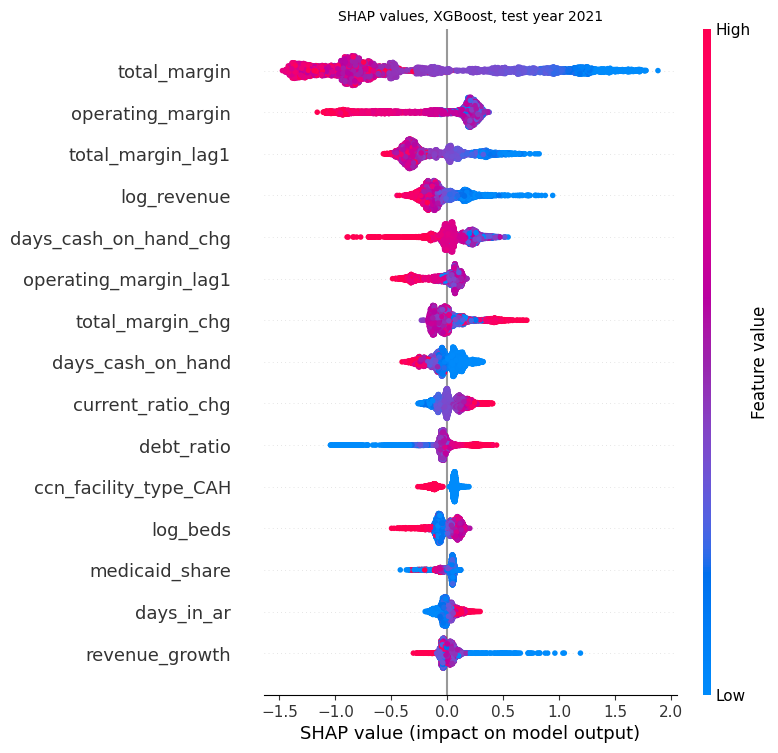

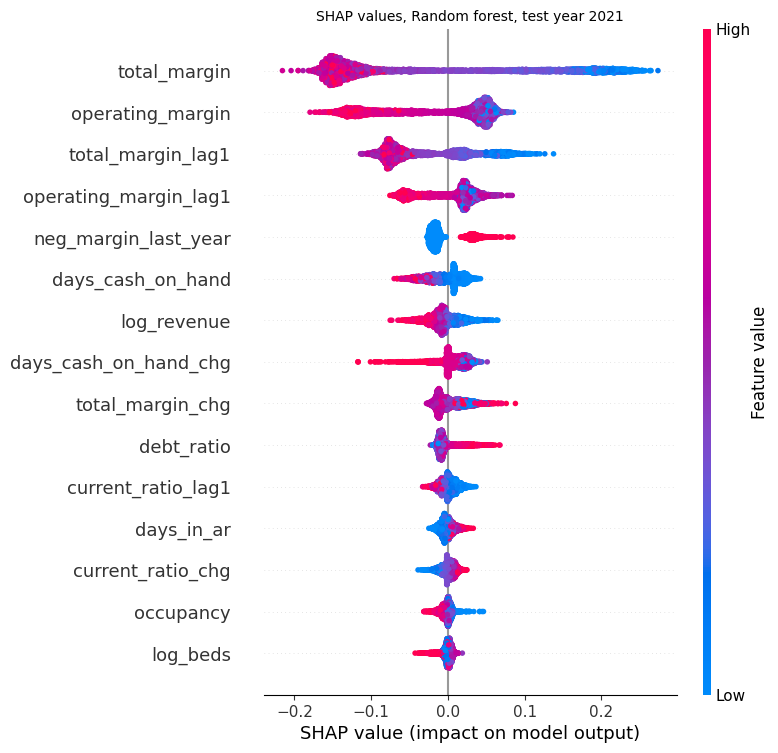

,XGB rank,RF rank
total_margin,1,1
operating_margin,2,2
total_margin_lag1,3,3
log_revenue,4,7
days_cash_on_hand_chg,5,8
operating_margin_lag1,6,4
total_margin_chg,7,9
days_cash_on_hand,8,6
current_ratio_chg,9,13
debt_ratio,10,10


Features in both models' top 10: 9 of 10


In [18]:
import shap
import matplotlib.pyplot as plt

FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

shap_results = {}
for chosen in ["XGBoost", "Random forest"]:
    model = fitted[chosen]
    prep, clf = model.named_steps["prep"], model.named_steps["clf"]

    X_test_t = prep.transform(X_test)
    if hasattr(X_test_t, "toarray"):
        X_test_t = X_test_t.toarray()
    names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]  # drop "num__" etc.

    sv = shap.TreeExplainer(clf).shap_values(X_test_t)
    if isinstance(sv, list):        # older shap: one array per class
        sv = sv[1]
    elif sv.ndim == 3:              # newer shap: (rows, features, classes)
        sv = sv[:, :, 1]

    shap_results[chosen] = pd.DataFrame(sv, columns=names, index=X_test.index)

    shap.summary_plot(sv, X_test_t, feature_names=names, max_display=15, show=False)
    plt.title(f"SHAP values, {chosen}, test year 2021", fontsize=10)
    plt.savefig(FIG_DIR / f"shap_summary_{chosen.lower().replace(' ', '_')}.png",
                dpi=300, bbox_inches="tight")
    plt.show()

# Compare the top drivers: rank features by mean |SHAP| in each model
rank = pd.DataFrame({m: df.abs().mean() for m, df in shap_results.items()})
rank["XGB rank"] = rank["XGBoost"].rank(ascending=False).astype(int)
rank["RF rank"] = rank["Random forest"].rank(ascending=False).astype(int)
top = rank.sort_values("XGB rank").head(15)
display(top[["XGB rank", "RF rank"]])

overlap = len(set(rank.nsmallest(10, "XGB rank").index) & set(rank.nsmallest(10, "RF rank").index))
print(f"Features in both models' top 10: {overlap} of 10")

In [19]:
REPORT_DIR = Path("..") / "reports" / "modeling"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

pd.DataFrame(cv_rows).round(4).to_csv(REPORT_DIR / "cv_rolling_pr_auc.csv", index=False)
val_table.to_csv(REPORT_DIR / "val_2020_cutoffs.csv", index=False)
results_table(y_test, test_scores).to_csv(REPORT_DIR / "test_2021_all.csv", index=False)
results_table(y_test, test_scores, mask=~term_test).to_csv(
    REPORT_DIR / "test_2021_excl_terminating.csv", index=False)
ci.round(4).to_csv(REPORT_DIR / "test_2021_bootstrap_ci.csv")
top.to_csv(REPORT_DIR / "shap_rank_xgb_vs_rf.csv")

print("Saved:", sorted(p.name for p in REPORT_DIR.glob("*.csv")))

Saved: ['cv_rolling_pr_auc.csv', 'shap_rank_xgb_vs_rf.csv', 'test_2021_all.csv', 'test_2021_bootstrap_ci.csv', 'test_2021_excl_terminating.csv', 'val_2020_cutoffs.csv']


In [20]:
import joblib

OUT_DIR = Path("..") / "data" / "outputs"
MODEL_DIR = Path("..") / "models"
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
CCN = "provider_ccn"

with sqlite3.connect(DB_PATH) as conn:
    allf = pd.read_sql("SELECT * FROM features", conn)
    clean_cols = pd.read_sql("PRAGMA table_info(cost_report_clean)", conn)["name"].tolist()
    info_cols = [c for c in ["hospital_name", "state_code", "city", "zip_code"] if c in clean_cols]
    print("Hospital info columns found:", info_cols)
    info = pd.read_sql(f"SELECT {CCN}, file_year, {', '.join(info_cols)} FROM cost_report_clean", conn)
allf[CCN] = allf[CCN].astype(str).str.zfill(6)
info[CCN] = info[CCN].astype(str).str.zfill(6)
allf[FLAGS] = allf[FLAGS].astype(float)

# 1. Train XGBoost (same settings) on every labeled year, 2015-2021
labeled = allf[allf[TARGET].notna()]
X_all, y_all = labeled[FEATURES], labeled[TARGET].astype(int)
deploy_model = make_xgb(y_all, 3, 10).fit(X_all, y_all)
joblib.dump(deploy_model, MODEL_DIR / "xgb_deploy.joblib")

# 2. Score the newest reports (2022 -> predicts distress in 2023)
now = allf[allf["file_year"] == allf["file_year"].max()].copy()
now["risk_score"] = deploy_model.predict_proba(now[FEATURES])[:, 1]
now["risk_percentile"] = now["risk_score"].rank(pct=True).round(3)
for k in (10, 20, 30):
    now[f"flag_top{k}"] = (now["risk_percentile"] > 1 - k / 100).astype(int)

# 3. SHAP: top 3 features pushing each hospital's risk UP
prep, clf = deploy_model.named_steps["prep"], deploy_model.named_steps["clf"]
Xt = prep.transform(now[FEATURES])
Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
sv = pd.DataFrame(shap.TreeExplainer(clf).shap_values(Xt), columns=names, index=now.index)

def drivers(row, n=3):
    up = row[row > 0].nlargest(n)
    return [f"{f} (+{v:.2f})" for f, v in up.items()] + [""] * (n - len(up))

d = sv.apply(drivers, axis=1, result_type="expand")
d.columns = ["driver_1", "driver_2", "driver_3"]
now = now.join(d).merge(info, on=[CCN, "file_year"], how="left")

# 4. Save the dashboard table
keep = [CCN, *info_cols, "file_year", "ccn_facility_type", "control_group", "rural_urban",
        "risk_score", "risk_percentile", "flag_top10", "flag_top20", "flag_top30",
        "driver_1", "driver_2", "driver_3",
        "total_margin", "operating_margin", "days_cash_on_hand", "current_ratio",
        "debt_ratio", "occupancy"]
dash = now[keep].sort_values("risk_score", ascending=False)
dash.to_csv(OUT_DIR / f"risk_scores_{int(now['file_year'].max())}.csv", index=False)
sv.assign(**{CCN: now[CCN].values}).to_csv(OUT_DIR / "shap_values_latest.csv", index=False)
with sqlite3.connect(DB_PATH) as conn:
    dash.to_sql("risk_scores_latest", conn, if_exists="replace", index=False)

print(f"Scored {len(dash):,} hospitals from {int(now['file_year'].max())}")
dash.head(10)

Hospital info columns found: ['hospital_name', 'state_code', 'city', 'zip_code']
Scored 4,536 hospitals from 2022


,provider_ccn,hospital_name,state_code,city,zip_code,file_year,ccn_facility_type,control_group,rural_urban,risk_score,...,flag_top30,driver_1,driver_2,driver_3,total_margin,operating_margin,days_cash_on_hand,current_ratio,debt_ratio,occupancy
3515,400133,HIMA SAN PABLO CUPEY,PR,SAN JUAN,00928,2022,STH,For-profit,U,0.972449,...,1,total_margin (+1.56),log_revenue (+0.66),revenue_growth (+0.54),-0.535788,-1.082039,19.942436,0.128800,3.401093,0.164594
3088,360247,PARKSIDE BEHAVIORAL HEALTHCARE ACQUI,OH,GAHANNA,43230,2022,STH,For-profit,U,0.968036,...,1,total_margin (+1.44),log_revenue (+0.55),revenue_growth (+0.47),-0.535788,-0.833816,-7.861102,0.299286,3.401093,0.243616
2241,250163,PATIENTS CHOICE MED CNT-SMITH CNTY,MS,RALEIGH,39153,2022,STH,For-profit,R,0.967786,...,1,total_margin (+1.38),log_revenue (+0.59),total_margin_lag1 (+0.42),-0.535788,-0.866224,10.177929,0.443581,1.955574,NaN
2600,310021,ST. FRANCIS - TRENTON,NJ,TRENTON,08629,2022,STH,Nonprofit,U,0.967516,...,1,total_margin (+1.49),total_margin_lag1 (+0.52),revenue_growth (+0.41),-0.535788,-1.082039,NaN,0.129443,3.401093,0.263092
2650,320003,ALTA VISTA REGIONAL HOSPITAL,NM,LAS VEGAS,87701,2022,STH,For-profit,R,0.966516,...,1,total_margin (+1.52),total_margin_lag1 (+0.42),debt_ratio (+0.25),-0.330400,-0.336467,-5.692514,0.128800,2.162547,0.094203
841,100298,FLORIDA STATE HOSPITAL,FL,CHATTACHOOCHEE,32324,2022,STH,Government,U,0.966400,...,1,total_margin (+1.49),log_revenue (+0.70),total_margin_lag1 (+0.50),-0.535788,-1.082039,NaN,NaN,1.000000,0.187329
1973,230096,STURGIS HOSPITAL INC.,MI,STURGIS,49091-,2022,STH,Nonprofit,R,0.965920,...,1,total_margin (+1.56),total_margin_lag1 (+0.45),debt_ratio (+0.28),-0.533035,-0.584084,-49.461464,NaN,3.401093,0.073917
4290,510093,MON HEALTH MARION NEIGHBORHOOD HOSPI,WV,WHITE HALL,26554,2022,STH,Nonprofit,R,0.965026,...,1,total_margin (+1.62),log_revenue (+0.77),debt_ratio (+0.25),-0.535788,-0.866351,7.994725,0.165569,1.694223,0.157609
2822,330411,UNITY SPECIALITY HOSPITAL,NY,ROCHESTER,14611,2022,STH,Nonprofit,U,0.963350,...,1,total_margin (+1.43),log_revenue (+0.48),total_margin_lag1 (+0.46),-0.535788,-1.082039,NaN,NaN,3.401093,NaN
3373,390119,MOSES TAYLOR HOSPITAL,PA,SCRANTON,18510-1798,2022,STH,For-profit,R,0.962997,...,1,total_margin (+1.47),revenue_growth (+0.48),total_margin_lag1 (+0.28),-0.335529,-0.361938,-0.699006,0.131603,1.391274,0.505350
